In [20]:
import pandas as pd
import requests
import os
from dotenv import load_dotenv
from datetime import date, timedelta
import time
import matplotlib.pyplot as plt

In [21]:
load_dotenv()
apikey = os.getenv("apikey")
url = "https://www.thecardapi.com/api/v1/market/sales"
query = "lebron james top prospects 2003 #3"
days = 365
starttime = (date.today() - timedelta(days = days)).isoformat()
params = {"q":query, "limit": 50, "date_from": starttime}
headers = {"x-market-api-key": apikey}

allresults = []
cursor = None
while True:
    if cursor:
        params["cursor"] = cursor
    response = requests.get(url, params = params, headers = headers)
    data = response.json()
    saledata = data.get("data", [])
    allresults.extend(saledata)
    cursor = data.get("pagination", {}).get("next_cursor")
    print("all finished")
    if not cursor:
        break
    time.sleep(.25)
df = pd.DataFrame(saledata)
df = df.dropna(subset=["price"])
df.head(25)

all finished


,id,platform,sales_channel,listing_type,title,sale_date,sold_at,price,price_usd,original_price,...,year,season,league,sport,team,features,print_run,shipping_price,category,player_identity
0,204432448864,eBay,NaN,fixed_price,2003-04 Lebron James UD Top Prospects #3 RC Ro...,2026-11-20,NaN,99.00,None,NaN,...,2003.0,2003-04,None,Basketball,None,[Rookie],None,0.00,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
1,800924903808,eBay,NaN,fixed_price,2003-04 Upper Deck UD Top Prospects - LeBron J...,2026-11-16,NaN,12.99,None,NaN,...,2003.0,2003-04,None,Basketball,None,[Rookie],None,1.36,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
3,880087485510,eBay,NaN,auction,2003 Upper Deck Top Prospects Lebron James Pro...,2026-11-13,NaN,122.50,None,NaN,...,2003.0,2003,None,Basketball,None,[Rookie],None,1.99,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
4,377627370382,eBay,NaN,auction,2003 Upper Deck Top Prospects LeBron James #3,2026-11-12,NaN,6.50,None,NaN,...,2003.0,2003,None,Basketball,None,[],None,5.75,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
7,227594729253,eBay,NaN,auction,2003-04 Upper Deck UD Top Prospects - LeBron J...,2026-11-09,NaN,90.00,None,NaN,...,2003.0,2003-04,None,Basketball,None,[Rookie],None,6.59,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
11,327413727378,eBay,NaN,auction,Upper Deck 2003 UD Top Prospects LeBron James ...,2026-10-27,NaN,37.78,None,NaN,...,NaN,NaN,None,NaN,None,[],None,NaN,sports,None
12,800810959875,eBay,NaN,auction,2003 Upper Deck Top Prospects #3 LeBron James ...,2026-10-26,NaN,9.52,None,NaN,...,NaN,NaN,None,NaN,None,[],None,NaN,sports,None
13,FC-SALE-v1|WEEKLY6715265,Fanatics Collect,weekly,auction,2003 Upper Deck Top Prospects LeBron James ROO...,2026-10-25,2026-10-26T03:23:35Z,288.00,None,NaN,...,2003.0,NaN,None,NaN,None,[],None,NaN,NaN,None
14,267815858995,eBay,NaN,auction,2003 UPPER DECK TOP PROSPECTS #3 LEBRON JAMES ...,2026-10-24,NaN,22.50,None,NaN,...,2003.0,2003,None,Basketball,None,[Rookie],None,6.25,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."
15,237122275144,eBay,NaN,auction,Lebron James 2003-04 Upper Deck Basketball UD ...,2026-10-23,NaN,5.52,None,NaN,...,2003.0,2003-04,None,Basketball,None,[],None,5.99,sports,"{'players': [{'name': 'LeBron James', 'upid': ..."


C:\Users\dylan\AppData\Local\Temp\ipykernel_30204\708429165.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(dailydf["sale_date"].tolist(), rotation = 30, ha = "right")


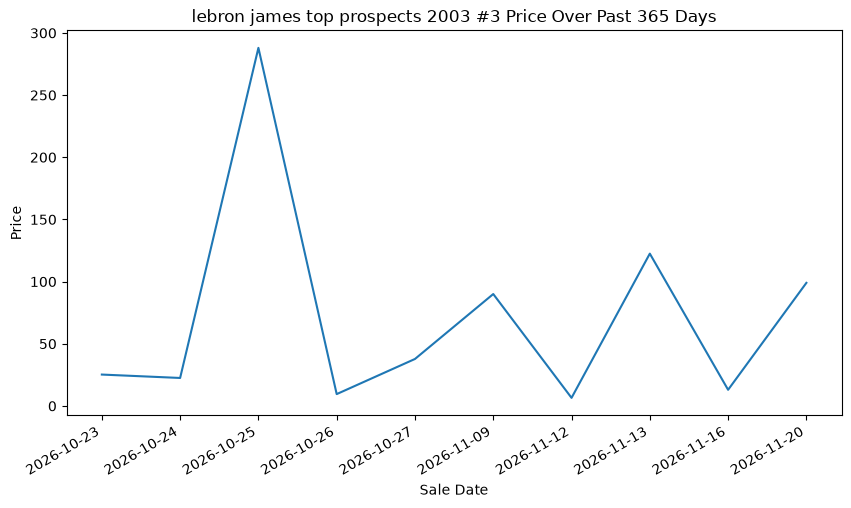

In [ ]:
dailydf = df.groupby("sale_date", as_index=False)["price"].mean()
fig, ax = plt.subplots(figsize = (10, 5))
ax.plot(dailydf["sale_date"], dailydf["price"])
ax.set_xlabel("Sale Date")
ax.set_ylabel("Price")
ax.set_title(f"{query} Price Over Past {days} Days")
ax.set_xticklabels(dailydf["sale_date"].tolist(), rotation = 30, ha = "right")
plt.show()